# Signed Inverse-Square SLAC Block Encoding

Explicit Qualtran circuits for a truncated SLAC operator, a recursive
Shannon wavelet transform, and two-sided wavelet preconditioning.

For $N=2^n$, the unnormalized target is
$$A=-\frac{\pi^2}{3}I+\sum_{j=1}^{N/2-1}\frac{2(-1)^{1+j}}{j^2}(S^j+S^{-j}).$$
Only $j=N/2$ is dropped. The diagonal is included once. Finite reference-register
precision approximates the inverse-square weights; this target differs from the
exact finite-periodic spectral Laplacian.

Run from the repository directory after installing `requirements.txt`.
Circuit definitions live in `slac_qualtran/circuits.py`; resource accounting and
analysis live in the two accompanying modules. All generated paths are relative.

In [1]:
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from slac_qualtran.circuits import (
    CompleteInverseSquareBlockEncoding, CompleteMultiscaleInverseSquare,
    circulant_from_column, inverse_square_column, shannon_multiscale_reference,
    shannon_dense_circuit_reference, shannon_rectangular_matrix_eq18,
    wavelet_scale_weights, slac_inverse_square_alpha,
)
from slac_qualtran.resources import (
    complete_inverse_square_counts, slac_rotation_audit, theoretical_component_table,
)
from slac_qualtran.analysis import (
    validate_complete_inverse_square_action, compare_three_slac_circuits,
    benchmark_complete_inverse_square_condition,
)

N_VALUES = range(3, 17)
RESULTS = Path("results")
RESULTS.mkdir(exist_ok=True)
print("Qualtran:", version("qualtran"))

Qualtran: 0.7.0


## Explicit Circuit Construction

The base circuit contains PREP (including the clean inequality test), parity
SIGN, failure COPY, SELECT, and PREP-adjoint. The multiscale circuit surrounds
it with $W$ and $W^\dagger$; the preconditioned circuit additionally uses two
independent signal ancillas to obtain $P W A W^\dagger P/\alpha_n$.

The normalization is $\alpha_n=\pi^2/3+8(1-2^{-(n-1)})$.
Shared QFT conjunctions and a reusable zero-prefix ladder reduce control costs.
There are still $2(n-1)$ one-scale QSWT calls across both transform directions.

In [2]:
n, n_ref = 3, 2*3 + 4
base = CompleteInverseSquareBlockEncoding(n, n_ref)
multiscale = CompleteMultiscaleInverseSquare(n, n_ref)
preconditioned = CompleteMultiscaleInverseSquare(n, n_ref, True)
base_circuit = base.decompose_bloq()
multiscale_circuit = multiscale.decompose_bloq()
preconditioned_circuit = preconditioned.decompose_bloq()
print("Base signature:", base.signature)
print("Normalization:", slac_inverse_square_alpha(n))
display(pd.DataFrame([
    {"circuit": label, **complete_inverse_square_counts(bloq)}
    for label, bloq in [("LCU", base), ("Multiscale", multiscale),
                        ("Preconditioned", preconditioned)]
]).fillna(0))

Base signature: Signature((Register(name='d', dtype=QBit(), _shape=(), side=<Side.THRU: 3>), Register(name='a', dtype=QBit(), _shape=(), side=<Side.THRU: 3>), Register(name='mu', dtype=QAny(bitsize=2), _shape=(), side=<Side.THRU: 3>), Register(name='j', dtype=QUInt(bitsize=2), _shape=(), side=<Side.THRU: 3>), Register(name='ref', dtype=QUInt(bitsize=10), _shape=(), side=<Side.THRU: 3>), Register(name='f', dtype=QBit(), _shape=(), side=<Side.THRU: 3>), Register(name='marker', dtype=QBit(), _shape=(), side=<Side.THRU: 3>), Register(name='sys', dtype=QUInt(bitsize=3), _shape=(), side=<Side.THRU: 3>)))
Normalization: 9.289868133696453


,circuit,rotation,clifford,toffoli,T
0,LCU,56,3169,1294,0.0
1,Multiscale,76,3283,1346,14.0
2,Preconditioned,86,3303,1350,14.0


## Encoded Action Checks

Small reference registers make exhaustive reversible inequality checks affordable
at N=8 and N=16. The resulting weights, signs, and actual SELECT actions are
compared with finite-precision circulant actions and independent FFT convolution.
The check also verifies the logical W/P composition. It does not contract the
complete circuit or execute a Cirq statevector simulation.

In [3]:
checks = []
for n in (3, 4):
    check = validate_complete_inverse_square_action(n, 3)
    w = shannon_multiscale_reference(n)
    filters, _, _ = shannon_rectangular_matrix_eq18(n)
    np.testing.assert_allclose(shannon_dense_circuit_reference(n), filters, atol=2e-12)
    np.testing.assert_allclose(w.conj().T @ w, np.eye(1 << n), atol=2e-12)
    p = np.diag(wavelet_scale_weights(n))
    target = circulant_from_column(inverse_square_column(n, 3)) / check["alpha_n"]
    np.testing.assert_allclose(p @ w @ check["encoded_action"] @ w.conj().T @ p,
                               p @ w @ target @ w.conj().T @ p, atol=2e-14)
    row = {k: v for k, v in check.items() if not isinstance(v, np.ndarray)}
    row["preconditioned_action_error"] = float(np.max(np.abs(
        p @ w @ (check["encoded_action"] - target) @ w.conj().T @ p)))
    checks.append(row)
action_checks = pd.DataFrame(checks)
action_checks.to_csv(RESULTS / "action_checks.csv", index=False)
display(action_checks)

,n,n_ref,alpha_n,classical_oracle_cases,finite_M_block_error,random_vector_action_error,raw_operator_rounding_error,rounding_error_bound,success_probability,preconditioned_action_error
0,3,3,9.289868,50,5.551115e-17,8.886120e-17,0.055556,0.750,0.946178,1.384292e-16
1,4,3,10.289868,114,2.775558e-17,8.441529e-17,0.109062,0.875,0.918002,4.549823e-17


## Analytical Counts Versus Qualtran

Each And and And-adjoint counts as one coherent Toffoli, including computation
and uncomputation. With $n_{ref}=2n+4$ and $n\ge3$, the analytically expected Toffoli counts:
$$T_{LCU}=100n^2+142n-32,$$
$$T_{MS}=(4n^3+327n^2+371n-126)/3,$$
$$T_{PMS}=(4n^3+327n^2+383n-150)/3.$$

These formulas describe the implemented schoolbook arithmetic and shared-control
decomposition. They exclude rotation synthesis, physical error correction,
nullspace projection circuits, and QLSA repetitions. They are not globally
minimal gate counts. No fitted scale factor is used.

,n,n_ref,LCU_analytical,LCU_circuit,multiscale_analytical,multiscale_circuit,preconditioned_analytical,preconditioned_circuit
0,3,10,1294,1294,1346,1346,1350,1350
1,4,12,2136,2136,2282,2282,2290,2290
2,5,14,3178,3178,3468,3468,3480,3480
3,6,16,4420,4420,4912,4912,4928,4928
4,7,18,5862,5862,6622,6622,6642,6642
5,8,20,7504,7504,8606,8606,8630,8630
6,9,22,9346,9346,10872,10872,10900,10900
7,10,24,11388,11388,13428,13428,13460,13460
8,11,26,13630,13630,16282,16282,16318,16318
9,12,28,16072,16072,19442,19442,19482,19482


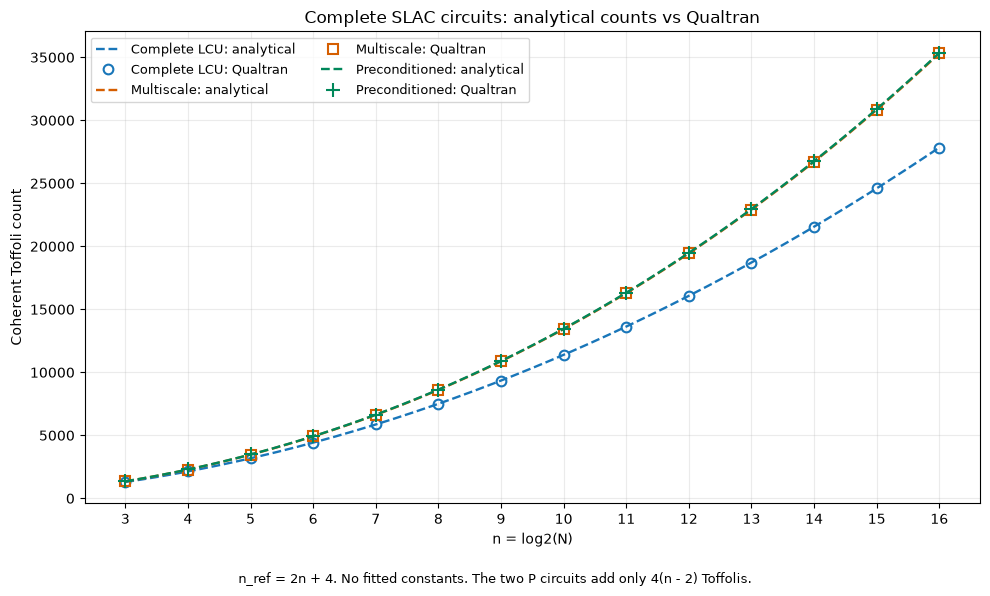

In [3]:
comparison, figure = compare_three_slac_circuits(N_VALUES)
comparison.to_csv(RESULTS / "toffoli_comparison.csv", index=False)
figure.savefig(RESULTS / "toffoli_comparison.png", dpi=180)
figure.savefig(RESULTS / "toffoli_comparison.pdf")
display(comparison)
display(figure)
plt.close(figure)

## Rotations Before Synthesis

The QFT uses controlled `PhaseGradientUnitary` gates. No phase-gradient state is
prepared and no phase-kickback addition is used. Generic Ry/Rz angles and phase
rotations requiring synthesis are shown separately from fixed pi/4-grid rotations.
The earlier logical rotation bucket includes all three categories.

,n,generic_Ry_Rz,fixed_pi_over_4_grid,unsynthesized_rotations,old_rotation_bucket,non_Clifford_T_phase
0,3,18,68,18,86,0.0
1,4,26,104,28,132,2.0
2,5,34,148,44,192,10.0
3,6,42,200,70,270,28.0
4,7,50,260,110,370,60.0
5,8,58,328,168,496,110.0
6,9,66,404,248,652,182.0
7,10,74,488,354,842,280.0
8,11,82,580,490,1070,408.0
9,12,90,680,660,1340,570.0


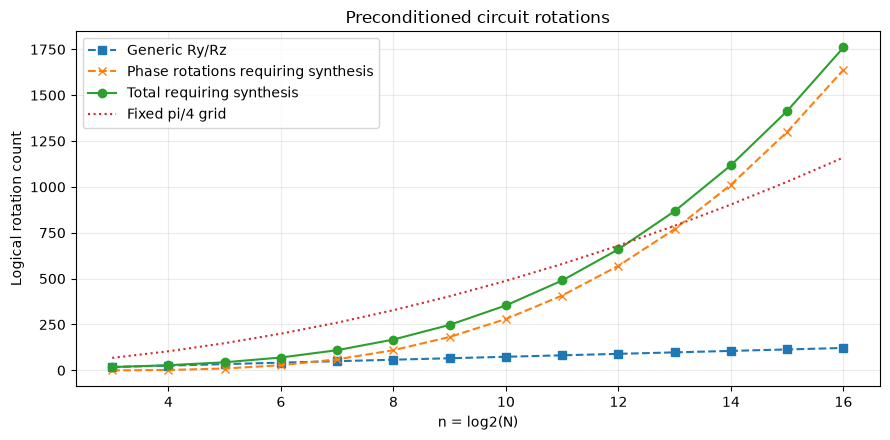

In [4]:
rotations = pd.DataFrame([
    {"n": n, **slac_rotation_audit(CompleteMultiscaleInverseSquare(n, 2*n + 4, True))}
    for n in N_VALUES
]).fillna(0)
rotations.to_csv(RESULTS / "rotations.csv", index=False)
figure, ax = plt.subplots(figsize=(9, 4.5))
for key, label, style in [
    ("generic_Ry_Rz", "Generic Ry/Rz", "s--"),
    ("non_Clifford_T_phase", "Phase rotations requiring synthesis", "x--"),
    ("unsynthesized_rotations", "Total requiring synthesis", "o-"),
    ("fixed_pi_over_4_grid", "Fixed pi/4 grid", ":"),
]:
    ax.plot(rotations["n"], rotations[key], style, label=label)
ax.set(xlabel="n = log2(N)", ylabel="Logical rotation count", title="Preconditioned circuit rotations")
ax.grid(alpha=0.25)
ax.legend()
figure.tight_layout()
figure.savefig(RESULTS / "rotations.png", dpi=180)
display(rotations)
display(figure)
plt.close(figure)

## Conditioning in the Multiscale Basis

The constant Fourier mode is excluded from these diagnostics. For the truncated
target it need not be an exact null mode. W alone preserves singular values;
two-sided P changes them. The curves compare the intended truncated operator and
the finite-reference approximation encoded by the circuit.

,n,N,n_ref,operator,kappa_constant_excluded,kappa_with_P_constant_excluded,constant_mode_eigenvalue
0,3,8,10,Exact truncated 1/j^2 target,11.259755,5.420125,0.154576
1,3,8,10,Finite-M complete circuit,11.251971,5.424414,0.155444
2,4,16,12,Exact truncated 1/j^2 target,49.283528,5.216255,0.035098
3,4,16,12,Finite-M complete circuit,49.293329,5.214477,0.035266
4,5,32,14,Exact truncated 1/j^2 target,205.128165,5.138689,0.008299
5,5,32,14,Finite-M complete circuit,205.169791,5.137854,0.008319
6,6,64,16,Exact truncated 1/j^2 target,836.095545,5.102584,0.002014
7,6,64,16,Finite-M complete circuit,837.135913,5.098024,0.002030
8,7,128,18,Exact truncated 1/j^2 target,3375.207366,5.084876,0.000496
9,7,128,18,Finite-M complete circuit,3379.011129,5.080817,0.000499


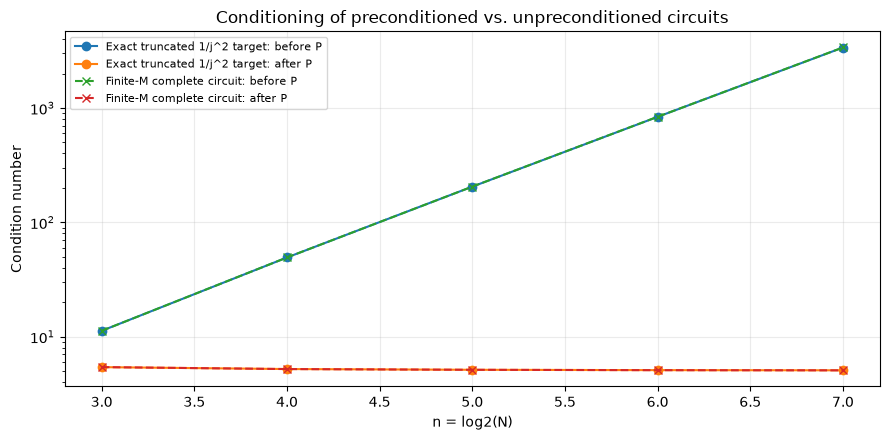

In [7]:
conditioning = benchmark_complete_inverse_square_condition(range(3, 8))
conditioning.to_csv(RESULTS / "conditioning.csv", index=False)
figure, ax = plt.subplots(figsize=(9, 4.5))
for kind, frame in conditioning.groupby("operator", sort=False):
    style = "o-" if kind.startswith("Exact") else "x--"
    ax.semilogy(frame["n"], frame["kappa_constant_excluded"], style, label=kind + ": before P")
    ax.semilogy(frame["n"], frame["kappa_with_P_constant_excluded"], style, label=kind + ": after P")
ax.set(xlabel="n = log2(N)", ylabel="Condition number", title="Conditioning of preconditioned vs. unpreconditioned circuits")
ax.grid(alpha=0.25)
ax.legend(fontsize=8)
figure.tight_layout()
figure.savefig(RESULTS / "conditioning.png", dpi=180)
display(conditioning)
display(figure)
plt.close(figure)

## Finite-Precision Coefficients

For reference size $M=2^{n_{ref}}$, an exact acceptance count produces each
finite-precision coefficient. At N=16 the unnormalized operator error is bounded
by $8(1-2^{-3})/M=7/M$.

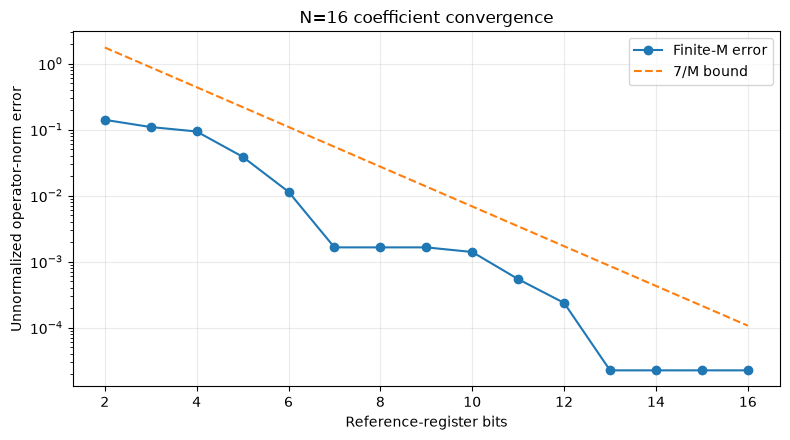

In [8]:
precision = []
for r in range(2, 17):
    error = float(np.max(np.abs(np.fft.fft(inverse_square_column(4, r) - inverse_square_column(4)))))
    bound = 7 / (1 << r)
    assert error < bound + 1e-14
    precision.append({"n_ref": r, "operator_error": error, "bound": bound})
precision = pd.DataFrame(precision)
precision.to_csv(RESULTS / "precision.csv", index=False)
figure, ax = plt.subplots(figsize=(8, 4.5))
ax.semilogy(precision["n_ref"], precision["operator_error"], "o-", label="Finite-M error")
ax.semilogy(precision["n_ref"], precision["bound"], "--", label="7/M bound")
ax.set(xlabel="Reference-register bits", ylabel="Unnormalized operator-norm error", title="N=16 coefficient convergence")
ax.grid(alpha=0.25)
ax.legend()
figure.tight_layout()
figure.savefig(RESULTS / "precision.png", dpi=180)
display(figure)
plt.close(figure)

## Component Accounting

This table shows the implemented arithmetic costs and separate logical gate
categories at n=16 and n_ref=36. Component rows and subtotal rows are not all
additive. The derivation note in `docs/` explains control reuse and the formulas.

In [9]:
components = theoretical_component_table(16, 36)
components.to_csv(RESULTS / "components.csv", index=False)
display(components)

,component,Toffoli_formula,theory_Toffoli,Qualtran_Toffoli,Clifford,explicit_T,logical_rotations
0,Square via schoolbook product,q(5q-1),1110,1110,1935,0,0
1,Product m*j^2,r(8q+r-1),5580,5580,10152,0,0
2,Comparator (one call),4(2q+r)-2,262,262,1312,0,0
3,Clean inequality oracle,2 Square + 2 Product + 2 Comparator + 1,13905,13905,26828,0,0
4,SELECT,2q,30,30,121,0,0
5,Complete base LCU,20q^2+32qr+4r^2+30q+12r-6,27840,27840,53999,0,264
6,W and W-adjoint,(4n^3+27n^2-55n-30)/3,7462,7462,4430,482,2594
7,Both P circuits,4(n-2),56,56,124,0,62
8,Full preconditioned circuit,base + W pair + P pair,35358,35358,58553,482,2920
